# Evaluating Classification

## A filter and one hundred messages

An inbox contains 20 spam messages and 80 legitimate messages. The actual labels stay fixed. Two controls set how many spam messages the filter catches and how many legitimate messages it hides by mistake. These are constructed predictions, so each kind of error can change independently.

A true positive (TP) is caught spam, and a false positive (FP) is a legitimate message hidden by mistake. A false negative (FN) is missed spam, and a true negative (TN) is a legitimate message kept. With this inbox, the remaining counts are

$$
FN=20-TP, \qquad TN=80-FP.
$$

The confusion matrix puts actual classes in rows and predicted actions in columns.

<img src="https://raw.githubusercontent.com/sonamu-jun/introduction-to-ai-convergence/main/07-1_Classification/assets/05_confusion_matrix.png" alt="A fixed inbox has 20 spam and 80 legitimate messages. Fourteen caught spam and eight false alarms determine all four confusion matrix counts." width="640" style="max-width:100%;height:auto;">

Each square in the screen is one message; a cross marks a filtered message. The square colors match the four matrix cells. Changing either count immediately updates the messages, matrix, and scores from the same predictions.


## What changes when the filter makes a mistake?

Precision asks how many filtered messages really are spam. Recall asks how much of the actual spam was caught:

$$
\mathrm{Precision}=\frac{TP}{TP+FP}, \qquad
\mathrm{Recall}=\frac{TP}{TP+FN}=\frac{TP}{20}.
$$

Increasing caught spam turns missed spam into true positives. Recall rises, and precision rises when false alarms are present. Increasing false alarms enlarges precision's denominator without adding caught spam, so precision falls when at least one spam message is caught. Recall stays fixed because the actual spam and caught spam counts have not changed.

Accuracy counts all correct predictions, including legitimate messages kept:

$$
\mathrm{Accuracy}=\frac{TP+TN}{100}.
$$

`Keep all` reaches 80% accuracy because legitimate messages are the majority, yet it catches no spam. `Filter all` catches every spam message, giving 100% recall, but only 20% precision because most hidden messages are legitimate.

F1 is the harmonic mean of precision and recall. Its count form is

$$
F_1=\frac{2TP}{2TP+FP+FN}.
$$

Both kinds of mistake reduce F1 relative to catching every spam message without false alarms. True negatives do not appear in its formula. The displayed fractions expose each metric's numerator and denominator. `Perfect` sets $TP=20$ and $FP=0$, making all four scores 100%.


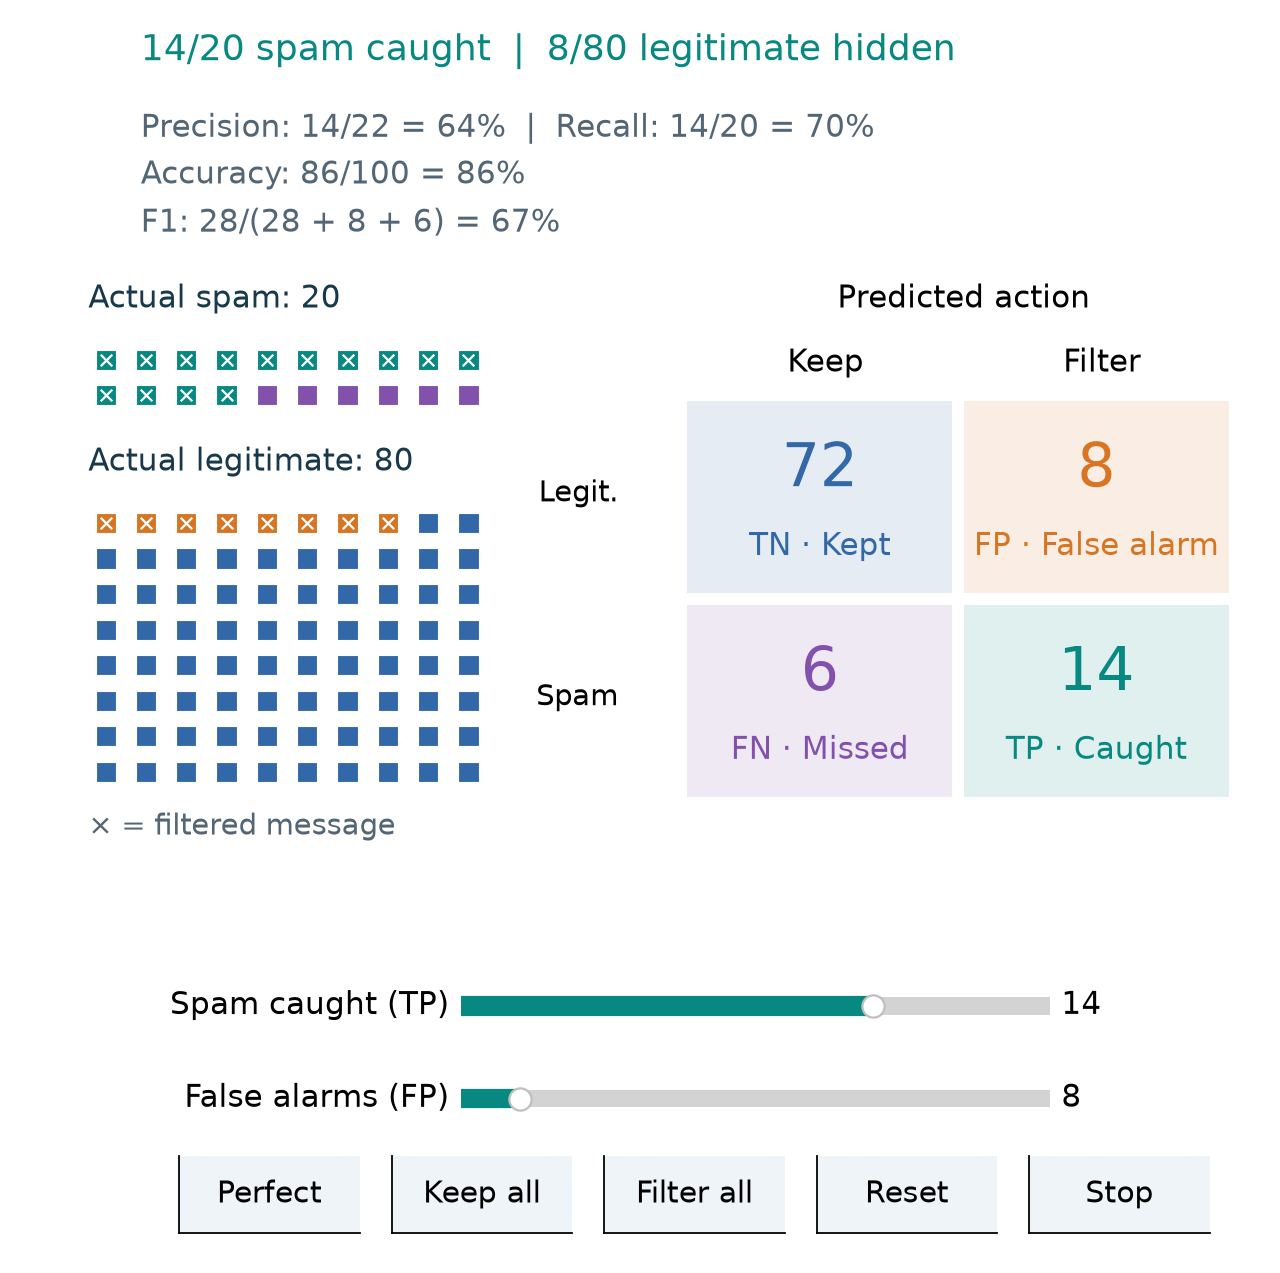

In [1]:
import os
import sys
import io
import numpy as np
import matplotlib

CLASSIFICATION_STATIC = os.environ.get("CLASSIFICATION_STATIC") == "1"
CLASSIFICATION_BROWSER = sys.platform == "emscripten"
if not CLASSIFICATION_STATIC and not CLASSIFICATION_BROWSER:
    from IPython import get_ipython
    shell = get_ipython()
    if shell is not None and getattr(shell, "kernel", None) is not None:
        shell.run_line_magic("matplotlib", "widget")

import matplotlib.pyplot as plt
from matplotlib.widgets import Slider, Button
from matplotlib.colors import ListedColormap
from IPython.display import Image, display
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

plt.rcParams.update({
    "font.size": 15, "axes.labelsize": 15,
    "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": .16, "lines.linewidth": 2.5,
    "axes.unicode_minus": False, "figure.facecolor": "white",
})
BLUE, TEAL, ORANGE, PURPLE = "#3268a8", "#078880", "#d87522", "#8251ac"


def sigmoid(score):
    score = np.clip(np.asarray(score, dtype=float), -500, 500)
    return 1 / (1 + np.exp(-score))


def softmax(scores):
    scores = np.asarray(scores, dtype=float)
    weights = np.exp(scores - scores.max(axis=-1, keepdims=True))
    return weights / weights.sum(axis=-1, keepdims=True)


def binary_loss(labels, scores):
    # The logaddexp form avoids taking log(0) at extreme scores.
    return float(np.mean(np.logaddexp(0, scores) - labels * scores))


def classification_metrics(observed, predicted):
    observed, predicted = np.asarray(observed), np.asarray(predicted)
    tp = int(np.sum((observed == 1) & (predicted == 1)))
    tn = int(np.sum((observed == 0) & (predicted == 0)))
    fp = int(np.sum((observed == 0) & (predicted == 1)))
    fn = int(np.sum((observed == 1) & (predicted == 0)))
    return {"TP": tp, "TN": tn, "FP": fp, "FN": fn,
            "accuracy": (tp + tn) / len(observed),
            "precision": tp / (tp + fp) if tp + fp else np.nan,
            "recall": tp / (tp + fn) if tp + fn else np.nan,
            "F1": 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else np.nan}


def percent(value):
    return "undefined" if not np.isfinite(value) else f"{value:.0%}"


# A rerun releases the previous figure and its input callbacks first.
for _previous_view in globals().get("_classification_views", {}).values():
    _previous_view.close()
_classification_views = {}


class ClassificationExplorer:
    """One figure keeps the selected model, predictions and scores together."""

    def __init__(self, name, render, sliders, actions=()):
        self.render = render
        self.slider_specs = sliders
        self.controls, self.buttons, self.state = {}, {}, {}
        self.stopped = False
        self.defaults = {key: initial for key, label, low, high, initial, step, fmt in sliders}
        with plt.ioff():
            height = min(8.0, 6.8 + .58 * len(sliders))
            self.figure = plt.figure(figsize=(8, height), dpi=80)
        self.status = self.figure.text(.11, 1 - .38 / height, "", fontsize=16, color=TEAL)
        self.detail = self.figure.text(.11, 1 - .66 / height, "", va="top", fontsize=14, color="#536675", linespacing=1.5)
        bottom = (1.38 + .58 * len(sliders)) / height
        top = 1 - 1.78 / height
        self.ax = self.figure.add_axes([.14, bottom, .81, top - bottom])
        for i, (key, label, low, high, initial, step, fmt) in enumerate(sliders):
            y = (.98 + .58 * (len(sliders) - i - 1)) / height
            slider = Slider(self.figure.add_axes([.36, y, .46, .22 / height]),
                            label, low, high, valinit=initial, valstep=step,
                            valfmt=fmt, color=TEAL)
            slider.label.set_fontsize(14)
            slider.valtext.set_fontsize(14)
            slider.on_changed(self.update)
            self.controls[key] = slider
        commands = list(actions) + [("Reset", lambda view: view.reset()),
                                    ("Stop", lambda view: view.stop())]
        self.commands = commands
        width = min(.25, .83 / len(commands) - .025)
        for i, (label, callback) in enumerate(commands):
            button = Button(self.figure.add_axes([.14 + i * (width + .025), .25 / height, width, .48 / height]),
                            label, color="#eef4f7", hovercolor="#d7e9e6")
            button.label.set_fontsize(13.5)
            button.on_clicked(lambda event, cb=callback: cb(self) if not self.stopped else None)
            self.buttons[label] = button
        self.figure.canvas.mpl_connect("close_event", lambda event: self.stop())
        _classification_views[name] = self
        self.update()

    def update(self, _=None):
        if self.stopped:
            return
        self.ax.clear()
        self.state = self.render(self, **{key: slider.val for key, slider in self.controls.items()})
        self.figure.canvas.draw_idle()
        self.refresh_local()

    def set_values(self, **values):
        if self.stopped:
            return
        for key, value in values.items():
            slider = self.controls[key]
            events, drawing = slider.eventson, slider.drawon
            slider.eventson = slider.drawon = False
            slider.set_val(value)
            slider.eventson, slider.drawon = events, drawing
        self.update()

    def reset(self):
        self.set_values(**self.defaults)

    def refresh_local(self):
        if not hasattr(self, "local_image"):
            return
        from matplotlib.transforms import Bbox
        width, height = self.figure.get_size_inches()
        # Crop only the embedded Matplotlib controls; native widgets follow the chart.
        lower = max(0, self.ax.get_position().y0 * height - .78)
        buffer = io.BytesIO()
        self.figure.savefig(buffer, format="png", dpi=80, facecolor="white",
                            bbox_inches=Bbox.from_extents(0, lower, width, height))
        self.local_image.value = buffer.getvalue()
        self.syncing_local = True
        for key, control in self.local_controls.items():
            control.value = self.controls[key].val
        self.syncing_local = False

    def start_local(self):
        from ipywidgets import Image as WidgetImage, FloatSlider, IntSlider
        from ipywidgets import Button as WidgetButton, HBox, VBox, Layout
        self.syncing_local = False
        self.local_image = WidgetImage(format="png", layout=Layout(
            width="100%", max_width="640px", height="auto"))
        self.local_controls, self.local_buttons = {}, {}
        for key, label, low, high, initial, step, fmt in self.slider_specs:
            slider_type = IntSlider if fmt == "%0.0f" and step == 1 else FloatSlider
            control = slider_type(value=initial, min=low, max=high, step=step,
                                  description=label, readout_format=fmt.replace("%0", ""),
                                  continuous_update=True,
                                  style={"description_width": "120px"},
                                  layout=Layout(width="100%", max_width="640px"))
            def changed(change, key=key):
                if not self.syncing_local and not self.stopped:
                    self.controls[key].set_val(change["new"])
            control.observe(changed, names="value")
            self.local_controls[key] = control
        for label, callback in self.commands:
            button = WidgetButton(description=label, layout=Layout(
                flex="1 1 0", min_width="120px", height="34px", margin="2px"))
            button.on_click(lambda _, cb=callback: cb(self) if not self.stopped else None)
            self.local_buttons[label] = button
        row = HBox(list(self.local_buttons.values()), layout=Layout(width="100%", flex_flow="row wrap"))
        self.local_row = row
        self.local_output = VBox([self.local_image, *self.local_controls.values(), row],
                                layout=Layout(width="100%", max_width="640px"))
        self.refresh_local()
        display(self.local_output)

    def start(self):
        if CLASSIFICATION_STATIC:
            buffer = io.BytesIO()
            self.figure.savefig(buffer, format="png", dpi=160, facecolor="white")
            display(Image(data=buffer.getvalue(), width=640,
                          alt=self.status.get_text() + ". " + self.detail.get_text()))
            plt.close(self.figure)
        elif CLASSIFICATION_BROWSER:
            # JSPCV sends mouse events after this cell has returned.
            plt.show(block=False)
        elif hasattr(self.figure.canvas, "toolbar_visible"):
            # The ipympl figure supplies a responsive chart with native widget controls.
            self.start_local()
        else:
            plt.show(block=False)

    def stop(self):
        if self.stopped:
            return
        self.stopped = True
        for control in list(self.controls.values()) + list(self.buttons.values()):
            control.set_active(False)
        for control in [*getattr(self, "local_controls", {}).values(),
                        *getattr(self, "local_buttons", {}).values()]:
            control.disabled = True
        if hasattr(self, "local_buttons"):
            self.local_buttons["Stop"].description = "Stopped"
        self.buttons["Stop"].label.set_text("Stopped")
        self.figure.canvas.draw_idle()

    def close(self):
        self.stop()
        for control in list(self.controls.values()) + list(self.buttons.values()):
            control.disconnect_events()
        plt.close(self.figure)
        if hasattr(self, "local_output"):
            self.local_output.close()
            self.local_image.close()
            self.local_row.close()
            for control in [*self.local_controls.values(), *self.local_buttons.values()]:
                control.close()



def make_messages(seed, count=240, spam_fraction=.35):
    """Synthetic labels and counts; no real messages or URLs are collected."""
    rng = np.random.default_rng(seed)
    labels = np.zeros(count, dtype=int)
    labels[:round(count * spam_fraction)] = 1
    rng.shuffle(labels)
    phrases = rng.binomial(10, np.where(labels == 1, .53, .13))
    links = rng.binomial(4, np.where(labels == 1, .57, .13))
    return np.column_stack([phrases, links]), labels


def make_fruit(seed):
    """Synthetic fruit measurements: hue in degrees and length / width."""
    rng = np.random.default_rng(seed)
    labels = np.repeat(np.arange(3), 60)
    centers = np.array([[8, 1.15], [30, 1.05], [53, 2.8]])
    spreads = np.array([[8, .18], [7, .16], [7, .5]])
    values = centers[labels] + rng.normal(size=(len(labels), 2)) * spreads[labels]
    return np.clip(values, [0, .7], [70, 4.2]), labels

# A controlled inbox isolates each kind of error; it is not a fitted model.
# Every displayed metric is computed from these same 100 labels and predictions.
actual_spam = 20
actual_legitimate = 80
observed = np.r_[np.ones(actual_spam, dtype=int), np.zeros(actual_legitimate, dtype=int)]


def render_messages(view, caught, false_alarms):
    caught, false_alarms = int(caught), int(false_alarms)
    predicted = np.zeros(len(observed), dtype=int)
    predicted[:caught] = 1
    predicted[actual_spam:actual_spam + false_alarms] = 1
    result = classification_metrics(observed, predicted)
    matrix = np.array([[result["TN"], result["FP"]], [result["FN"], result["TP"]]])
    tp, fp, fn, tn = (result[name] for name in ["TP", "FP", "FN", "TN"])
    filtered = tp + fp
    ax = view.ax
    position = ax.get_position()
    ax.set_position([.06, position.y0, .90, position.height])
    ax.set(xlim=(0, 1), ylim=(0, 1))
    ax.axis("off")
    # One square is one message. Crosses indicate the messages the filter hides.
    ax.text(.01, .96, "Actual spam: 20", fontsize=14, color="#17394b")
    ax.text(.01, .68, "Actual legitimate: 80", fontsize=14, color="#17394b")
    message_index = np.arange(len(observed))
    group_index = np.where(observed == 1, message_index, message_index - actual_spam)
    x = .025 + (group_index % 10) * .035
    y = np.where(observed == 1, .87, .59) - (group_index // 10) * .061
    colors = np.where(observed == 1, np.where(predicted == 1, TEAL, PURPLE),
                      np.where(predicted == 1, ORANGE, BLUE))
    ax.scatter(x, y, marker="s", s=82, c=colors, edgecolor="white", linewidth=.5)
    hidden = predicted == 1
    ax.scatter(x[hidden], y[hidden], marker="x", s=27, color="white", linewidth=1)
    ax.text(.01, .055, "× = filtered message", fontsize=13, color="#536675")
    # Keep the conventional matrix orientation: actual rows, predicted columns.
    ax.text(.77, .96, "Predicted action", ha="center", fontsize=14)
    ax.text(.65, .85, "Keep", ha="center", fontsize=14)
    ax.text(.89, .85, "Filter", ha="center", fontsize=14)
    ax.text(.47, .64, "Legit.", ha="right", va="center", fontsize=13)
    ax.text(.47, .29, "Spam", ha="right", va="center", fontsize=13)
    cells = [(0, 0, tn, "TN · Kept", BLUE), (0, 1, fp, "FP · False alarm", ORANGE),
             (1, 0, fn, "FN · Missed", PURPLE), (1, 1, tp, "TP · Caught", TEAL)]
    from matplotlib.patches import Rectangle
    for row, col, count, label, color in cells:
        x = .53 + col * .24
        y = .47 - row * .35
        ax.add_patch(Rectangle((x, y), .23, .33, facecolor=color, alpha=.12, edgecolor="none"))
        ax.text(x + .115, y + .21, str(count), ha="center", va="center", fontsize=27, color=color)
        ax.text(x + .115, y + .065, label, ha="center", fontsize=14, color=color)
    view.status.set_text(f"{tp}/20 spam caught  |  {fp}/80 legitimate hidden")
    precision = f"{tp}/{filtered} = {percent(result['precision'])}" if filtered else "0/0 → undefined"
    view.detail.set_text(
        f"Precision: {precision}  |  Recall: {tp}/20 = {percent(result['recall'])}\n"
        f"Accuracy: {tp + tn}/100 = {percent(result['accuracy'])}\n"
        f"F1: {2 * tp}/({2 * tp} + {fp} + {fn}) = {percent(result['F1'])}")
    return {"prediction": predicted, "observed": observed.copy(), "metrics": result,
            "matrix": matrix, "filtered": filtered}


spam_demo = ClassificationExplorer("spam", render_messages, [
    ("caught", "Spam caught (TP)", 0, actual_spam, 14, 1, "%0.0f"),
    ("false_alarms", "False alarms (FP)", 0, actual_legitimate, 8, 1, "%0.0f"),
], actions=[
    ("Perfect", lambda view: view.set_values(caught=20, false_alarms=0)),
    ("Keep all", lambda view: view.set_values(caught=0, false_alarms=0)),
    ("Filter all", lambda view: view.set_values(caught=20, false_alarms=80)),
])
spam_demo.start()


## From controlled errors to a real classifier

With `Keep all`, no messages are filtered, so precision has denominator zero and is undefined. Recall and F1 are zero because the inbox contains spam and none is caught. A classifier can therefore have respectable accuracy while failing completely at finding the positive class.

The two controls isolate error types for comparison; a real filter cannot choose TP and FP independently. Lowering a probability threshold usually catches more spam and also creates more false alarms. The binary logistic regression example changes both through a single threshold.

These scores describe the constructed inbox, not measured performance of a trained model. A real evaluation uses labeled messages excluded from fitting, chooses settings with validation data, and reports final performance on an untouched test set. The useful balance depends on the cost of hiding legitimate messages versus missing spam; no single score expresses every cost.
